# HW#5 -- Part II: Summarization by Fine-Tuning Encoder-Decoder Models

**Name:** Asad Khan
**Course:** CSC 583 -- Natural Language Processing, Fall 2026
**Assignment:** HW#5, Part II
**Collaborators:** None. GenAI disclosure: Claude (Anthropic) was used as a coding assistant.

## 0. Setup

The starter mounts Google Drive only for output persistence. I ran this notebook **locally**
(Apple M4, PyTorch `mps` backend) in the course's uv environment, so outputs are simply written
next to the notebook and the Colab-only lines are kept as comments. The SAMSum dataset and all
model checkpoints are still pulled from the HuggingFace Hub.

In [1]:
# Colab only -- not needed when running locally
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
import os

# thisdir = "/content/drive/My Drive/CSC583_Fall2026/HW5"   # Colab
thisdir = os.getcwd()                                       # local: the HW5 folder
os.chdir(thisdir)
print(thisdir)

/Users/asadkhan/workspace/depaul/NLP/HW5


In [3]:
# Already installed in the local uv environment (see NLP/pyproject.toml)
# !pip install -q -U transformers tokenizers accelerate huggingface_hub datasets evaluate sentencepiece rouge_score bert_score

In [4]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # keep the baked-in outputs readable
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset, disable_progress_bars
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    AutoModelForCausalLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    TrainerCallback,
    set_seed,
)
from transformers.utils import logging as hf_logging
from evaluate import load as load_metric
import transformers

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
disable_progress_bars()
set_seed(42)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"    # Apple Silicon GPU
else:
    device = "cpu"
print("Using device:", device)
print("torch", torch.__version__, "| transformers", transformers.__version__)

Using device: mps
torch 2.14.0 | transformers 5.17.0


## 1. Load the SAMSum dataset

`knkarthick/samsum` comes split into train/validation/test; I use those splits as-is.
`'dialogue'` is the original text and `'summary'` is the reference summary.

In [5]:
raw_ds = load_dataset("knkarthick/samsum")
print(raw_ds)

lens = {split: pd.Series([len((d or "").split()) for d in raw_ds[split]["dialogue"]]) for split in raw_ds}
sum_lens = {split: pd.Series([len((s or "").split()) for s in raw_ds[split]["summary"]]) for split in raw_ds}
print(pd.DataFrame({f"{s} dialogue words": lens[s].describe() for s in raw_ds}).round(1))
print(pd.DataFrame({f"{s} summary words": sum_lens[s].describe() for s in raw_ds}).round(1))

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
})
       train dialogue words  validation dialogue words  test dialogue words
count               14731.0                      818.0                819.0
mean                   93.8                       91.6                 95.5
std                    74.0                       74.5                 75.2
min                     7.0                       10.0                  9.0
25%                    39.0                       38.0                 42.0
50%                    73.0                       70.0                 74.0
75%                   128.0                      127.0                126.0
max                   803.0                      540.0                51

In [6]:
# A few rows have a missing or empty dialogue/summary; check before tokenizing
for split in raw_ds:
    bad = sum(1 for d, s in zip(raw_ds[split]["dialogue"], raw_ds[split]["summary"])
              if not d or not s or not d.strip() or not s.strip())
    print(f"{split:10s} rows with an empty dialogue or summary: {bad}")
print("\nExample:\n", raw_ds["train"][0]["dialogue"], "\n--> ", raw_ds["train"][0]["summary"])

train      rows with an empty dialogue or summary: 0
validation rows with an empty dialogue or summary: 0
test       rows with an empty dialogue or summary: 0

Example:
 Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-) 
-->  Amanda baked cookies and will bring Jerry some tomorrow.


## 2. Load model + tokenizer

I fine-tune `google-t5/t5-small` (the same checkpoint used as the off-the-shelf model in Part I,
so the two parts tell one consistent story). Section 4 evaluates this exact checkpoint first.

In [7]:
model_name = "google-t5/t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)
print(f"{model_name}: {sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters")

google-t5/t5-small: 60.5M parameters


## 3. Build the test-set evaluation pipeline (ROUGE + Perplexity + BERTScore)

Built once, before training, and reused unchanged for the original model (Section 4) and the
fine-tuned model (Section 8). The test set is tokenized with `padding=True` and
`.set_format("torch")`, as in Part I. Perplexity uses the GPT-2 workaround from the assignment's
KNOWN ISSUE note.

In [8]:
from torch.utils.data import DataLoader

prefix = "summarize: "
# same decoding as Part I, for every model evaluated on the test set
GEN_KWARGS = dict(max_new_tokens=128, num_beams=4, no_repeat_ngram_size=3, early_stopping=True)

def prepare_for_inference(dataset, tokenizer, text_column="dialogue", max_length=512):
    def tok(examples):
        inputs = [prefix + doc for doc in examples[text_column]]
        return tokenizer(inputs, max_length=max_length, padding=True, truncation=True)
    # one map batch = whole split, so padding=True gives every row the same length
    ds = dataset.map(tok, batched=True, batch_size=len(dataset), remove_columns=dataset.column_names)
    ds.set_format("torch")
    return ds

def generate_summaries(model, tokenizer, tokenized_ds, batch_size=32, **gen_kwargs):
    gen_kwargs = {**GEN_KWARGS, **gen_kwargs}
    model.eval()
    loader = DataLoader(tokenized_ds, batch_size=batch_size)
    predictions = []
    with torch.no_grad():
        for batch in loader:
            out = model.generate(input_ids=batch["input_ids"].to(model.device),
                                 attention_mask=batch["attention_mask"].to(model.device),
                                 **gen_kwargs)
            predictions.extend(tokenizer.batch_decode(out, skip_special_tokens=True))
    return [p.strip() for p in predictions]

rouge = load_metric("rouge")
bertscore = load_metric("bertscore")

gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
gpt2_model = AutoModelForCausalLM.from_pretrained("gpt2").to(device)
gpt2_model.eval()

def compute_mean_perplexity(texts, max_length=1024):
    perplexities = []
    with torch.no_grad():
        for text in texts:
            enc = gpt2_tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length)
            input_ids = enc["input_ids"].to(device)
            if input_ids.size(1) < 2:
                continue   # too short to compute a next-token loss on
            loss = gpt2_model(input_ids, labels=input_ids).loss
            perplexities.append(torch.exp(loss).item())
    return float(np.mean(perplexities))   # this is 'mean_perplexity'

def evaluate_summaries(predictions, references):
    preds = [p if p.strip() else "." for p in predictions]   # guard against empty strings
    r = rouge.compute(predictions=preds, references=references)
    bs = bertscore.compute(predictions=preds, references=references, lang="en")
    return {
        "rouge1": r["rouge1"],
        "rouge2": r["rouge2"],
        "rougeL": r["rougeL"],
        "mean_perplexity": compute_mean_perplexity(preds),
        "bertscore_precision": float(np.mean(bs["precision"])),
        "bertscore_recall": float(np.mean(bs["recall"])),
        "bertscore_f1": float(np.mean(bs["f1"])),
        "mean_words": float(np.mean([len(p.split()) for p in preds])),
    }

test_ds_raw = raw_ds["test"]
test_tokenized = prepare_for_inference(test_ds_raw, tokenizer, "dialogue")
references = list(test_ds_raw["summary"])
print("test_tokenized:", test_tokenized, "| input_ids shape:", tuple(test_tokenized[:]["input_ids"].shape))
print(f"Reference summaries: {np.mean([len(r.split()) for r in references]):.1f} words on average, "
      f"GPT-2 perplexity {compute_mean_perplexity(references):.2f}")

test_tokenized: Dataset({
    features: ['input_ids', 'attention_mask'],
    num_rows: 819
}) | input_ids shape: (819, 512)


Reference summaries: 20.0 words on average, GPT-2 perplexity 128.65


## 4. Baseline: run and evaluate the ORIGINAL (off-the-shelf) model, BEFORE fine-tuning

In [9]:
t0 = time.time()
original_predictions = generate_summaries(model, tokenizer, test_tokenized)
original_metrics = evaluate_summaries(original_predictions, references)
print(f"Done in {time.time() - t0:.0f}s")
pd.Series(original_metrics).round(4)

Done in 255s


rouge1                   0.2732
rouge2                   0.0714
rougeL                   0.2127
mean_perplexity        138.2837
bertscore_precision      0.8568
bertscore_recall         0.8813
bertscore_f1             0.8687
mean_words              21.5531
dtype: float64

In [10]:
for i in range(3):
    print(f"[{i}] REF: {references[i]}\n    T5 : {original_predictions[i]}\n")

[0] REF: Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.
    T5 : Amanda: Lemme check Hannah: file_gif> Amanda: Sorry, can't find it. he called her last time we were at the park together Hannah: I don't know him well.

[1] REF: Eric and Rob are going to watch a stand-up on youtube.
    T5 : Rob: I know! I especially like the train part! Rob: Hahaha! No one talks to the machine like that! I'll watch some of his stand-ups on youtube.

[2] REF: Lenny can't decide which trousers to buy. Bob advised Lenny on that topic. Lenny goes with Bob's advice to pick the trousers that are of best quality.
    T5 : Bob: what matters is what you'll give you the most outfit options. Bob: pick the best quality then Lenny: ur right, thx Bob: no prob.



## 5. Preprocess the training data into a tokenized `DatasetDict`

- Optional clean-up step: drop rows with an empty dialogue/summary, strip non-ASCII characters
  (emoji, odd quotes) and collapse whitespace (`\r\n` line breaks become spaces, which is what the
  T5 SentencePiece tokenizer does to newlines anyway).
- Inputs get the `"summarize: "` prefix and are truncated at 512 tokens; targets come from
  `tokenizer(text_target=...)`, truncated at 128 tokens.
- **No padding here**: `DataCollatorForSeq2Seq` pads each batch dynamically and sets padded label
  positions to -100 so they are ignored by the loss.

In [11]:
import re

def clean_text(text):
    text = text.encode("ascii", errors="ignore").decode()   # remove non-ascii characters
    return re.sub(r"\s+", " ", text).strip()

def preprocess_function(examples):
    inputs = [prefix + clean_text(doc) for doc in examples["dialogue"]]
    model_inputs = tokenizer(inputs, max_length=512, truncation=True)
    labels = tokenizer(text_target=[clean_text(s) for s in examples["summary"]], max_length=128, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

non_empty = raw_ds.filter(lambda ex: bool(ex["dialogue"] and ex["dialogue"].strip()
                                          and ex["summary"] and ex["summary"].strip()))
tokenized_ds = non_empty.map(preprocess_function, batched=True, remove_columns=raw_ds["train"].column_names)
print(tokenized_ds)

in_len = [len(x) for x in tokenized_ds["train"]["input_ids"]]
lab_len = [len(x) for x in tokenized_ds["train"]["labels"]]
print(f"train inputs: mean {np.mean(in_len):.0f} tokens, max {max(in_len)}, truncated {sum(l == 512 for l in in_len)}")
print(f"train labels: mean {np.mean(lab_len):.0f} tokens, max {max(lab_len)}")

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 818
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 819
    })
})
train inputs: mean 149 tokens, max 512, truncated 167
train labels: mean 29 tokens, max 93


## 6. Set up the evaluator used *during training* (on the validation set)

In [12]:
def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    result = rouge.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
    result = {k: round(v, 4) for k, v in result.items()}
    result["gen_len"] = float(np.mean([np.count_nonzero(p != tokenizer.pad_token_id) for p in preds]))
    return result

## 7. Train the model (3 epochs)

Use `Seq2SeqTrainingArguments` + `Seq2SeqTrainer`. The results reported during training are with
respect to the **validation** set, not train.

Fixed settings for every run:

| parameter | value | why |
|---|---|---|
| epochs | 3 (main run) | required |
| schedule | linear decay, 5% warm-up | standard for T5 fine-tuning |
| batch size | 16 (train), 32 (eval) | fits easily in memory |
| weight decay | 0.01 | mild regularization |
| input / target length | 512 / 128 tokens | covers almost all dialogues (see Section 5) |
| eval generation | greedy, up to 64 new tokens | SAMSum summaries average ~20 words; keeps per-epoch validation fast |

**A note on running this on a Mac (MPS backend).** My first attempt ran out of memory: the PyTorch
MPS allocator keeps a cached buffer for every distinct batch shape, and with dynamic padding almost
every batch has a new shape, so the process grew to 24 GB and started swapping. Two changes fix it:
the collator pads every batch to a multiple of 64 tokens (only a handful of distinct shapes), and a
small callback releases the MPS cache every 50 steps and after each evaluation.

In [13]:
STEPS_PER_EPOCH = int(np.ceil(len(tokenized_ds["train"]) / 16))

def make_collator(tok, mdl):
    return DataCollatorForSeq2Seq(tokenizer=tok, model=mdl, pad_to_multiple_of=64)

class ReleaseMPSCache(TrainerCallback):
    """Free cached MPS buffers regularly so memory stays flat on Apple Silicon."""
    def on_step_end(self, args, state, control, **kwargs):
        if device == "mps" and state.global_step % 50 == 0:
            torch.mps.empty_cache()
    def on_evaluate(self, args, state, control, **kwargs):
        if device == "mps":
            torch.mps.empty_cache()
            print(f"  [epoch {state.epoch:.0f}] MPS memory after eval: {torch.mps.driver_allocated_memory()/1e9:.2f} GB")

def make_training_args(output_dir, learning_rate, **overrides):
    args = dict(
        output_dir=output_dir,
        num_train_epochs=3,
        learning_rate=learning_rate,
        lr_scheduler_type="linear",
        warmup_steps=0.05,   # a float < 1 is a ratio of total steps in transformers 5
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="rougeL",
        greater_is_better=True,
        predict_with_generate=True,
        generation_max_length=64,
        logging_strategy="steps",
        logging_steps=50,
        report_to="none",
        seed=42,
        dataloader_pin_memory=False,
        disable_tqdm=True,
    )
    args.update(overrides)
    return Seq2SeqTrainingArguments(**args)

def epoch_table(log_history):
    """One row per epoch: last logged training loss + the validation metrics."""
    evals = [h for h in log_history if "eval_loss" in h]
    trains = [h for h in log_history if "loss" in h and "eval_loss" not in h]
    rows = []
    for e in evals:
        before = [t["loss"] for t in trains if t["step"] <= e["step"]]
        rows.append({"epoch": round(e["epoch"]), "step": e["step"], "train_loss (last log)": before[-1] if before else np.nan,
                     "val_loss": e["eval_loss"], "val_rouge1": e["eval_rouge1"], "val_rouge2": e["eval_rouge2"],
                     "val_rougeL": e["eval_rougeL"], "val_gen_len": e["eval_gen_len"]})
    return pd.DataFrame(rows).set_index("epoch")

### 7a. Experimenting with the parameters (quick learning-rate check)

The HF summarization guide uses `learning_rate=2e-5`, while T5 models are commonly fine-tuned with
much larger rates (around 1e-4 to 1e-3). A full 3-epoch run takes roughly an hour on this laptop, so
I compared the two choices cheaply: each one trains a **fresh copy** of `t5-small` for 1 epoch on
a fixed random 2,000 training dialogues and is scored on 200 validation dialogues. The `model`
object evaluated in Section 4 is not touched here; the winner is used for the full run in 7b.

In [14]:
sweep_train = tokenized_ds["train"].shuffle(seed=42).select(range(2000))
sweep_val = tokenized_ds["validation"].select(range(200))

SWEEP = {"lr=2e-5 (HF guide)": 2e-5, "lr=3e-4": 3e-4}
sweep_rows, sweep_losses = {}, {}

for name, lr in SWEEP.items():
    set_seed(42)
    exp_model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)
    exp_trainer = Seq2SeqTrainer(
        model=exp_model,
        args=make_training_args("sweep-tmp", learning_rate=lr, num_train_epochs=1, save_strategy="no",
                                load_best_model_at_end=False, logging_steps=10),
        train_dataset=sweep_train,
        eval_dataset=sweep_val,
        processing_class=tokenizer,
        data_collator=make_collator(tokenizer, exp_model),
        compute_metrics=compute_metrics,
        callbacks=[ReleaseMPSCache()],
    )
    t0 = time.time()
    exp_trainer.train()
    ev = [h for h in exp_trainer.state.log_history if "eval_loss" in h][-1]
    sweep_rows[name] = {"learning_rate": lr, "val_loss": ev["eval_loss"], "val_rouge1": ev["eval_rouge1"],
                        "val_rouge2": ev["eval_rouge2"], "val_rougeL": ev["eval_rougeL"], "val_gen_len": ev["eval_gen_len"],
                        "minutes": (time.time() - t0) / 60}
    sweep_losses[name] = [(h["step"], h["loss"]) for h in exp_trainer.state.log_history
                          if "loss" in h and "eval_loss" not in h]
    del exp_model, exp_trainer
    if device == "mps":
        torch.mps.empty_cache()

sweep_summary = pd.DataFrame(sweep_rows).T
BEST_LR = float(sweep_summary.loc[sweep_summary["val_rougeL"].astype(float).idxmax(), "learning_rate"])
print("Learning rate used for the full run:", BEST_LR)
sweep_summary.round(4)

{'loss': '3.099', 'grad_norm': '4.128', 'learning_rate': '1.966e-05', 'epoch': '0.08'}


{'loss': '2.811', 'grad_norm': '3.529', 'learning_rate': '1.797e-05', 'epoch': '0.16'}


{'loss': '2.627', 'grad_norm': '4.627', 'learning_rate': '1.627e-05', 'epoch': '0.24'}


{'loss': '2.556', 'grad_norm': '2.209', 'learning_rate': '1.458e-05', 'epoch': '0.32'}


{'loss': '2.637', 'grad_norm': '2.229', 'learning_rate': '1.288e-05', 'epoch': '0.4'}


{'loss': '2.499', 'grad_norm': '3.205', 'learning_rate': '1.119e-05', 'epoch': '0.48'}


... (17 outputs left out)

{'loss': '2.095', 'grad_norm': '1.798', 'learning_rate': '4.068e-05', 'epoch': '0.88'}


{'loss': '2.127', 'grad_norm': '2.385', 'learning_rate': '1.525e-05', 'epoch': '0.96'}


{'eval_loss': '1.879', 'eval_rouge1': '0.3945', 'eval_rouge2': '0.1625', 'eval_rougeL': '0.3268', 'eval_rougeLsum': '0.3261', 'eval_gen_len': '20.95', 'eval_runtime': '8.887', 'eval_samples_per_second': '22.5', 'eval_steps_per_second': '0.788', 'epoch': '1'}
  [epoch 1] MPS memory after eval: 4.63 GB
{'train_runtime': '149', 'train_samples_per_second': '13.42', 'train_steps_per_second': '0.839', 'train_loss': '2.188', 'epoch': '1'}
Learning rate used for the full run: 0.0003


,learning_rate,val_loss,val_rouge1,val_rouge2,val_rougeL,val_gen_len,minutes
lr=2e-5 (HF guide),0.0000,2.1702,0.3377,0.1167,0.2714,25.36,2.4856
lr=3e-4,0.0003,1.8794,0.3945,0.1625,0.3268,20.95,2.4868


### 7b. Configure the main run (full training set, chosen learning rate)

This trains `model` in place -- the same object already evaluated as the untouched baseline in
Section 4.

In [15]:
data_collator = make_collator(tokenizer, model)
training_args = make_training_args("t5-small-samsum-checkpoints", learning_rate=BEST_LR)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[ReleaseMPSCache()],
)
print("learning rate:", BEST_LR, "| steps per epoch:", STEPS_PER_EPOCH, "| total steps:", 3 * STEPS_PER_EPOCH)

learning rate: 0.0003 | steps per epoch: 921 | total steps: 2763


### 7c. Train, and save the fine-tuned model to disk

In [16]:
t0 = time.time()
train_output = trainer.train()
print(f"Training time: {(time.time() - t0)/60:.1f} min")
print(train_output)

trainer.save_model("t5-small-samsum-finetuned")
tokenizer.save_pretrained("t5-small-samsum-finetuned")

{'loss': '2.657', 'grad_norm': '2.241', 'learning_rate': '0.0001058', 'epoch': '0.05429'}


{'loss': '2.219', 'grad_norm': '2.504', 'learning_rate': '0.0002137', 'epoch': '0.1086'}


{'loss': '2.142', 'grad_norm': '1.899', 'learning_rate': '0.0002989', 'epoch': '0.1629'}


{'loss': '2.114', 'grad_norm': '1.965', 'learning_rate': '0.0002931', 'epoch': '0.2172'}


{'loss': '2.051', 'grad_norm': '2.203', 'learning_rate': '0.0002874', 'epoch': '0.2714'}


{'loss': '2.047', 'grad_norm': '1.749', 'learning_rate': '0.0002817', 'epoch': '0.3257'}


... (51 outputs left out)

{'eval_loss': '1.655', 'eval_rouge1': '0.4751', 'eval_rouge2': '0.2358', 'eval_rougeL': '0.3959', 'eval_rougeLsum': '0.3953', 'eval_gen_len': '23.09', 'eval_runtime': '39.64', 'eval_samples_per_second': '20.63', 'eval_steps_per_second': '0.656', 'epoch': '3'}
  [epoch 3] MPS memory after eval: 4.59 GB


{'train_runtime': '3195', 'train_samples_per_second': '13.83', 'train_steps_per_second': '0.865', 'train_loss': '1.82', 'epoch': '3'}


Training time: 53.3 min
TrainOutput(global_step=2763, training_loss=1.8202849535505452, metrics={'train_runtime': 3194.9202, 'train_samples_per_second': 13.832, 'train_steps_per_second': 0.865, 'train_loss': 1.8202849535505452, 'epoch': 3.0})


('t5-small-samsum-finetuned/tokenizer_config.json',
 't5-small-samsum-finetuned/tokenizer.json')

,step,train_loss (last log),val_loss,val_rouge1,val_rouge2,val_rougeL,val_gen_len
epoch,,,,,,,
1,921,1.9045,1.7210,0.4541,0.2176,0.3791,23.0220
2,1842,1.7360,1.6617,0.4651,0.2240,0.3855,23.4401
3,2763,1.6567,1.6552,0.4751,0.2358,0.3959,23.0880


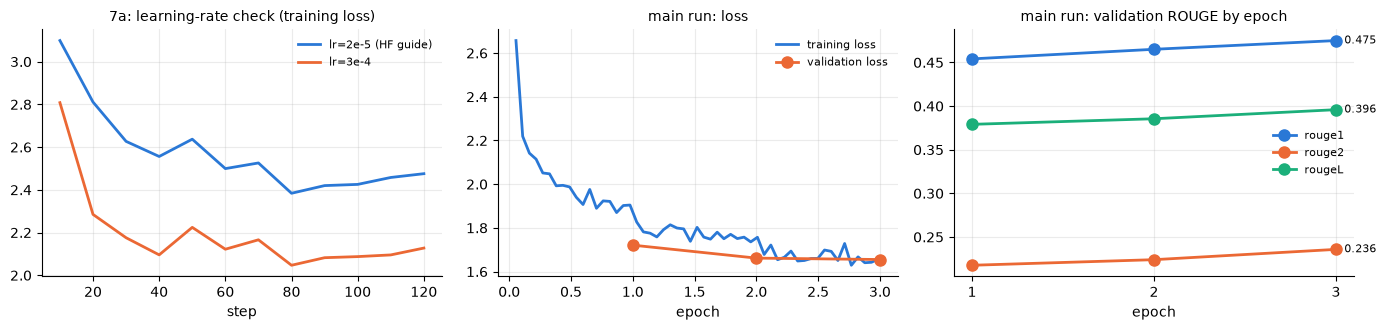

In [17]:
# Per-epoch results on the VALIDATION set, as reported by the trainer during training
main_epochs = epoch_table(trainer.state.log_history)
display(main_epochs.round(4))

main_losses = [(h["epoch"], h["loss"]) for h in trainer.state.log_history if "loss" in h and "eval_loss" not in h]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for color, (name, pts) in zip(["#2a78d6", "#eb6834"], sweep_losses.items()):
    s, l = zip(*pts)
    axes[0].plot(s, l, color=color, lw=2, label=name)
axes[0].set_title("7a: learning-rate check (training loss)", fontsize=10); axes[0].set_xlabel("step")
axes[0].legend(fontsize=8, frameon=False)
ep, losses = zip(*main_losses)
axes[1].plot(ep, losses, color="#2a78d6", lw=2, label="training loss")
axes[1].plot(main_epochs.index, main_epochs["val_loss"], color="#eb6834", lw=2, marker="o", ms=8, label="validation loss")
axes[1].set_title("main run: loss", fontsize=10); axes[1].legend(fontsize=8, frameon=False); axes[1].set_xlabel("epoch")
for col, color in [("val_rouge1", "#2a78d6"), ("val_rouge2", "#eb6834"), ("val_rougeL", "#1baf7a")]:
    axes[2].plot(main_epochs.index, main_epochs[col], color=color, lw=2, marker="o", ms=8, label=col.replace("val_", ""))
    axes[2].annotate(f"{main_epochs[col].iloc[-1]:.3f}", (main_epochs.index[-1], main_epochs[col].iloc[-1]), xytext=(6, 0),
                     textcoords="offset points", va="center", fontsize=8)
axes[2].set_title("main run: validation ROUGE by epoch", fontsize=10); axes[2].legend(fontsize=8, frameon=False)
axes[2].set_xticks(list(main_epochs.index)); axes[2].set_xlabel("epoch")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("part2_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Evaluate the FINE-TUNED model on the TEST set

Reloaded fresh from disk, then run through the exact same `generate_summaries` /
`evaluate_summaries` pipeline from Section 3 (same tokenized test set, same beam search).

In [18]:
finetuned_model = AutoModelForSeq2SeqLM.from_pretrained("t5-small-samsum-finetuned").to(device)
finetuned_tokenizer = AutoTokenizer.from_pretrained("t5-small-samsum-finetuned")

t0 = time.time()
finetuned_predictions = generate_summaries(finetuned_model, finetuned_tokenizer, test_tokenized)
finetuned_metrics = evaluate_summaries(finetuned_predictions, references)
print(f"Done in {time.time() - t0:.0f}s")
pd.Series(finetuned_metrics).round(4)

Done in 216s


rouge1                   0.4647
rouge2                   0.2279
rougeL                   0.3856
mean_perplexity        144.1231
bertscore_precision      0.9209
bertscore_recall         0.9139
bertscore_f1             0.9172
mean_words              16.9841
dtype: float64

## 9. Compare the ORIGINAL (baseline) model with the fine-tuned model

In [19]:
comparison = pd.DataFrame({"original (off-the-shelf)": original_metrics, "fine-tuned": finetuned_metrics})
comparison["change"] = comparison["fine-tuned"] - comparison["original (off-the-shelf)"]
comparison.round(4)

,original (off-the-shelf),fine-tuned,change
rouge1,0.2732,0.4647,0.1915
rouge2,0.0714,0.2279,0.1565
rougeL,0.2127,0.3856,0.1729
mean_perplexity,138.2837,144.1231,5.8394
bertscore_precision,0.8568,0.9209,0.0640
bertscore_recall,0.8813,0.9139,0.0325
bertscore_f1,0.8687,0.9172,0.0485
mean_words,21.5531,16.9841,-4.5690


In [20]:
# Per-dialogue view: how often does fine-tuning help, and does the baseline just copy the dialogue?
r_orig = rouge.compute(predictions=[p or "." for p in original_predictions], references=references, use_aggregator=False)
r_ft = rouge.compute(predictions=[p or "." for p in finetuned_predictions], references=references, use_aggregator=False)
better = np.sum(np.array(r_ft["rougeL"]) > np.array(r_orig["rougeL"]))
print(f"Fine-tuned ROUGE-L higher on {better}/{len(references)} test dialogues")

def starts_with_speaker(s):
    return bool(re.match(r"^[A-Z][\w ]{0,20}:", s))
print(f"Summaries that start like a dialogue turn ('Name: ...'): original {np.mean([starts_with_speaker(p) for p in original_predictions]):.1%}, "
      f"fine-tuned {np.mean([starts_with_speaker(p) for p in finetuned_predictions]):.1%}")

def first_person(s):
    return bool(re.search(r"\b(I|I'm|I'll|my|me|we|you)\b", s))
print(f"Summaries using first/second person: original {np.mean([first_person(p) for p in original_predictions]):.1%}, "
      f"fine-tuned {np.mean([first_person(p) for p in finetuned_predictions]):.1%}, "
      f"reference {np.mean([first_person(r) for r in references]):.1%}")

Fine-tuned ROUGE-L higher on 708/819 test dialogues
Summaries that start like a dialogue turn ('Name: ...'): original 55.8%, fine-tuned 0.0%
Summaries using first/second person: original 82.1%, fine-tuned 0.2%, reference 0.6%


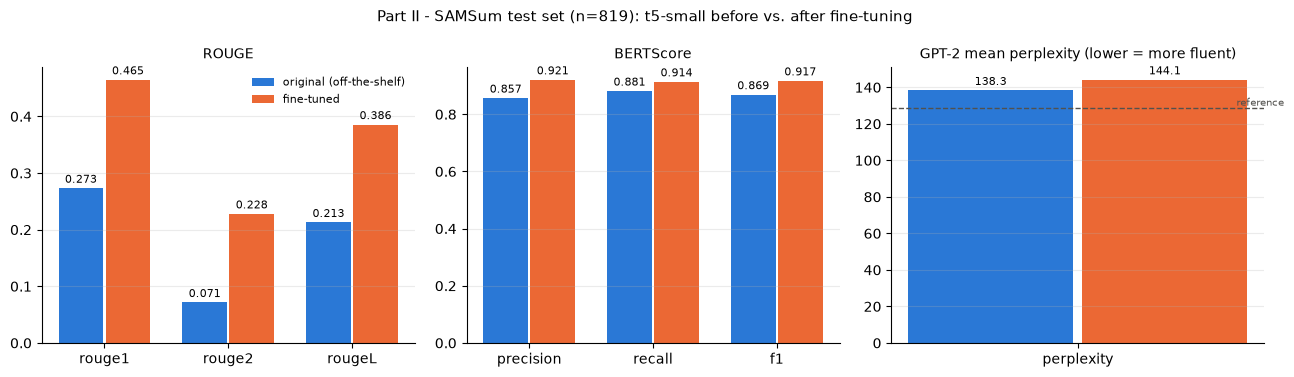

In [21]:
COLORS = {"original (off-the-shelf)": "#2a78d6", "fine-tuned": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
groups = [("ROUGE", ["rouge1", "rouge2", "rougeL"]),
          ("BERTScore", ["bertscore_precision", "bertscore_recall", "bertscore_f1"]),
          ("GPT-2 mean perplexity (lower = more fluent)", ["mean_perplexity"])]
for ax, (title, cols) in zip(axes, groups):
    x = np.arange(len(cols)); w = 0.38
    for i, lab in enumerate(COLORS):
        bars = ax.bar(x + (i - 0.5) * w, comparison.loc[cols, lab], w - 0.02, color=COLORS[lab], label=lab)
        ax.bar_label(bars, fmt="%.1f" if cols[0] == "mean_perplexity" else "%.3f", fontsize=8, padding=2)
    ax.set_xticks(x, [c.replace("bertscore_", "").replace("mean_", "") for c in cols])
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
axes[2].axhline(compute_mean_perplexity(references), color="#52514e", ls="--", lw=1)
axes[2].text(0.45, compute_mean_perplexity(references), "reference", fontsize=7, va="bottom", ha="right", color="#52514e")
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle("Part II - SAMSum test set (n=819): t5-small before vs. after fine-tuning", fontsize=11)
fig.tight_layout()
fig.savefig("part2_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Two qualitative examples: ground truth vs. generated (before/after fine-tuning)

The same two indices are reused in Part III.

In [22]:
import textwrap

example_idx = [10, 50]

for i in example_idx:
    print("=" * 110)
    print(f"Test index {i}  (id {test_ds_raw[i]['id']})")
    print("=" * 110)
    print("DIALOGUE:\n" + test_ds_raw[i]["dialogue"] + "\n")
    for title, text in [("REFERENCE", references[i]),
                        (f"ORIGINAL t5-small  [ROUGE-L {r_orig['rougeL'][i]:.3f}]", original_predictions[i]),
                        (f"FINE-TUNED t5-small [ROUGE-L {r_ft['rougeL'][i]:.3f}]", finetuned_predictions[i])]:
        print(f"{title}:\n" + textwrap.fill(text, 105, initial_indent="    ", subsequent_indent="    ") + "\n")

Test index 10  (id 13680771)
DIALOGUE:
Wanda: Let's make a party!
Gina: Why?
Wanda: beacuse. I want some fun!
Gina: ok, what do u need?
Wanda: 1st I need too make a list
Gina: noted and then?
Wanda: well, could u take yours father car and go do groceries with me?
Gina: don't know if he'll agree
Wanda: I know, but u can ask :)
Gina: I'll try but theres no promisess
Wanda: I know, u r the best!
Gina: When u wanna go
Wanda: Friday?
Gina: ok, I'll ask

REFERENCE:
    Wanda wants to throw a party. She asks Gina to borrow her father's car and go do groceries together.
    They set the date for Friday.

ORIGINAL t5-small  [ROUGE-L 0.154]:
    Gina: ok, what do u need? Wanda: I know, u r the best!

FINE-TUNED t5-small [ROUGE-L 0.278]:
    Gina and Wanda will go to a party on Friday.

Test index 50  (id 13728057-1)
DIALOGUE:
Nick: You look absolutely gorgeous and have a lovely smile. 
Nick: Would love to get to know you a bit more. How about we meet up for a drink sometime?
Jane: Hmmm... You're

## 11. Save results (for the write-up)

In [23]:
comparison.round(4).to_csv("part2_comparison.csv")
main_epochs.round(4).to_csv("part2_training_epochs.csv")
sweep_summary.round(4).to_csv("part2_sweep.csv")

pd.DataFrame([{"idx": i, "dialogue": test_ds_raw[i]["dialogue"], "reference": references[i],
               "original": original_predictions[i], "fine_tuned": finetuned_predictions[i]}
              for i in example_idx]).to_csv("part2_examples.csv", index=False)

# Full test-set predictions (Part III reuses these to compare against the LLM on the same dialogues)
pd.DataFrame({"idx": range(len(references)), "id": list(test_ds_raw["id"]), "reference": references,
              "original": original_predictions, "fine_tuned": finetuned_predictions}).to_csv(
    "part2_test_predictions.csv", index=False)
print("Saved part2_comparison.csv, part2_training_epochs.csv, part2_sweep.csv, "
      "part2_examples.csv, part2_test_predictions.csv and the figures")

Saved part2_comparison.csv, part2_training_epochs.csv, part2_sweep.csv, part2_examples.csv, part2_test_predictions.csv and the figures
